# Replogle real data: IV, SV, GMM under Wald and local-robust inference

This notebook **only reads computed results and makes tables/figures**. The PCA and model-fitting workflow now runs via `python code/experiments/replogle/run_replogle.py` and writes to `results/replogle/`. Inputs remain in `data/`. We use the same perturbation–outcome pairs for both inference rules; BH adjustment is within perturbation and method (q ≤ 0.05). Local inference uses the existing ellipsoidal moment-deviation set with κ_IV = κ_SV = 0.5. These figures describe discoveries, not simulation power or Type I error.

The SRP-scale design uses 213 perturbations × 2,000 non-target outcomes. If the result files still come from the earlier 19-outcome run, rerun both Replogle scripts before executing this notebook.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Patch
from IPython.display import Image, display

root = Path.cwd()
if not (root / 'results' / 'replogle' / 'iv_sv_gmm_results.csv.gz').is_file():
    root = root / 'unification-control-modelling'
out = root / 'results' / 'replogle'
required = ['iv_sv_gmm_results.csv.gz', 'pca_explained_variance.csv', 'pca_scores.csv.gz', 'wilcoxon_matched_raw.csv.gz']
missing = [name for name in required if not (out / name).is_file()]
if missing:
    raise FileNotFoundError(f'Missing computed results: {missing}. Run python code/experiments/replogle/run_replogle.py first.')
results = pd.read_csv(out / 'iv_sv_gmm_results.csv.gz')
variance = pd.read_csv(out / 'pca_explained_variance.csv')
scores = pd.read_csv(out / 'pca_scores.csv.gz')
wilcoxon = pd.read_csv(out / 'wilcoxon_matched_raw.csv.gz')
methods = ('iv', 'sv', 'gmm')
labels = {'iv': 'IV', 'sv': 'SV', 'gmm': 'Two-step GMM'}
colors = {'iv': '#42677B', 'sv': '#9A675B', 'gmm': '#68846B'}
alpha = 0.05
for name in ('top20_de_genes_by_perturbation.csv.gz', 'common_1000_non_de_genes.csv', 'global_top20_de_genes.csv', 'outcome_genes.csv', 'first_stage_results.csv', 'skipped_models.csv'):
    print(name, 'available:', (out / name).is_file())
print(f'{len(results):,} fitted perturbation–outcome pairs; {results.perturbation.nunique()} perturbations; {results.y_gene.nunique()} outcomes.')
assert not results.duplicated(['perturbation', 'y_gene']).any()
if results['y_gene'].nunique() != 2000 or results['perturbation'].nunique() * 2000 != len(results):
    raise RuntimeError('These CSVs are not the SRP-scale 2,000-outcome run. Rerun run_replogle.py and run_go_analysis.py before executing the notebook.')
assert not wilcoxon.duplicated(['perturbation', 'y_gene']).any()
display(pd.read_csv(out / 'first_stage_results.csv').head())

top20_de_genes_by_perturbation.csv.gz available: True
common_1000_non_de_genes.csv available: True
global_top20_de_genes.csv available: True
outcome_genes.csv available: True
first_stage_results.csv available: True
skipped_models.csv available: True
426,000 fitted perturbation–outcome pairs; 213 perturbations; 2000 outcomes.


,perturbation,x_gene,n_samples,n_treated,n_control,n_batches,first_stage_beta,first_stage_se,first_stage_p,first_stage_F
0,AATF,AATF,86,38,48,48,-0.567039,0.034032,2.488190e-62,277.612491
1,ABCF1,ABCF1,85,37,48,48,-0.413237,0.069752,3.135368e-09,35.097912
2,AHCTF1,AHCTF1,86,38,48,48,-0.519712,0.046539,5.891696e-29,124.709550
3,ALYREF,ALYREF,83,35,48,48,-0.324008,0.051821,4.040789e-10,39.093055
4,ANAPC15,ANAPC15,95,47,48,48,-0.109354,0.034675,1.612338e-03,9.945606


## PCA diagnostics

The retained PC count is unchanged (10). The plots below are regenerated from saved PCA scores and variance, not from raw H5AD data.

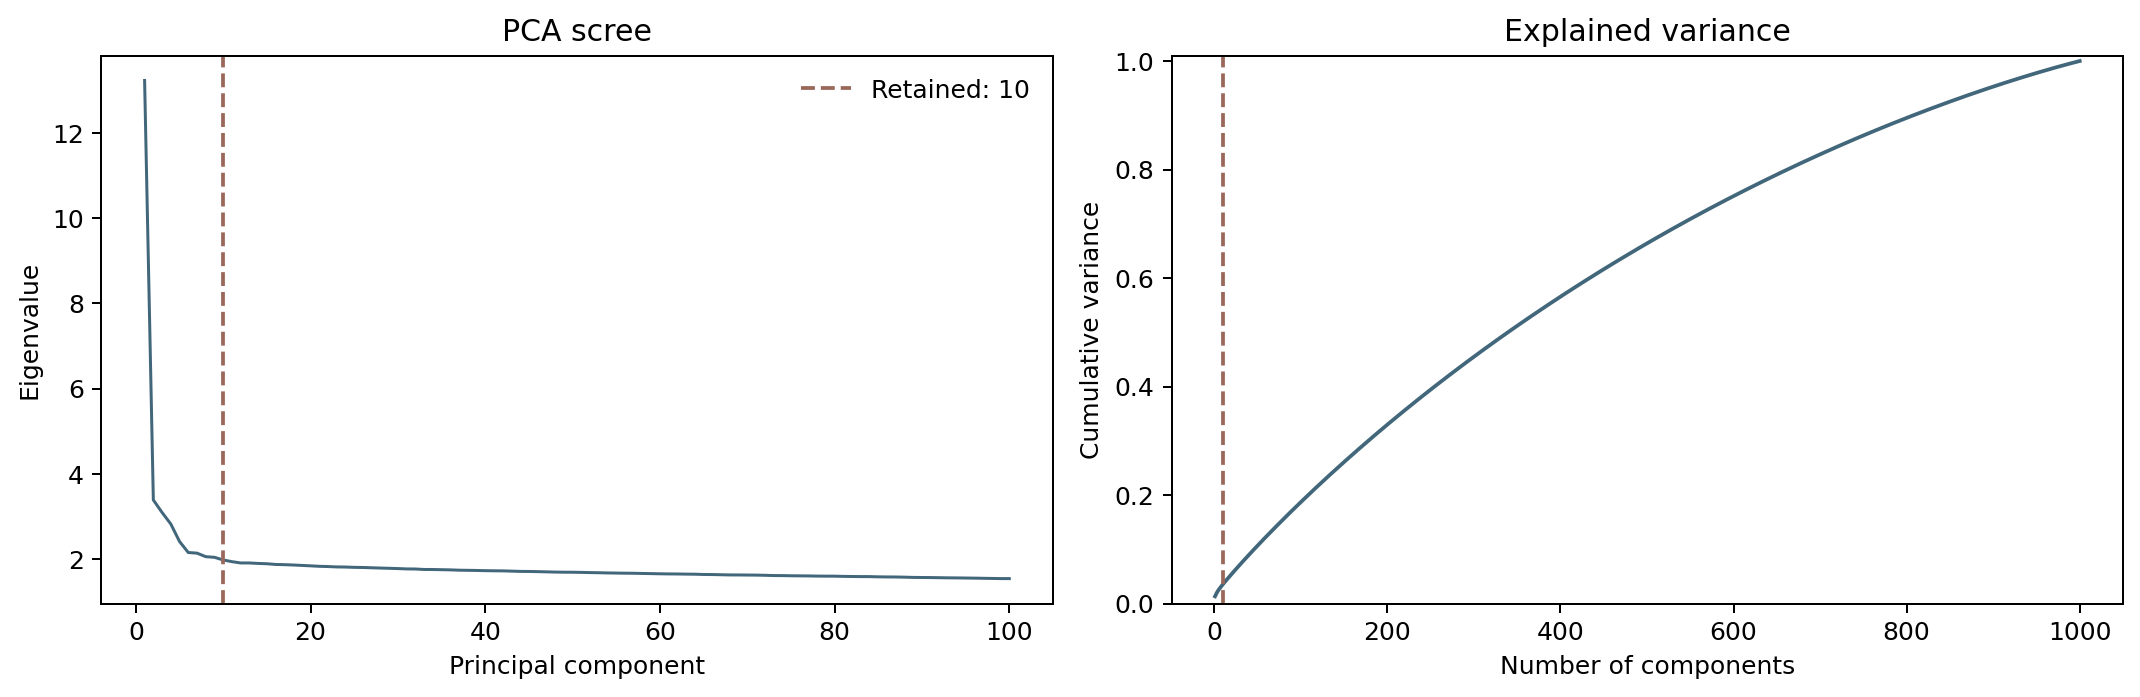

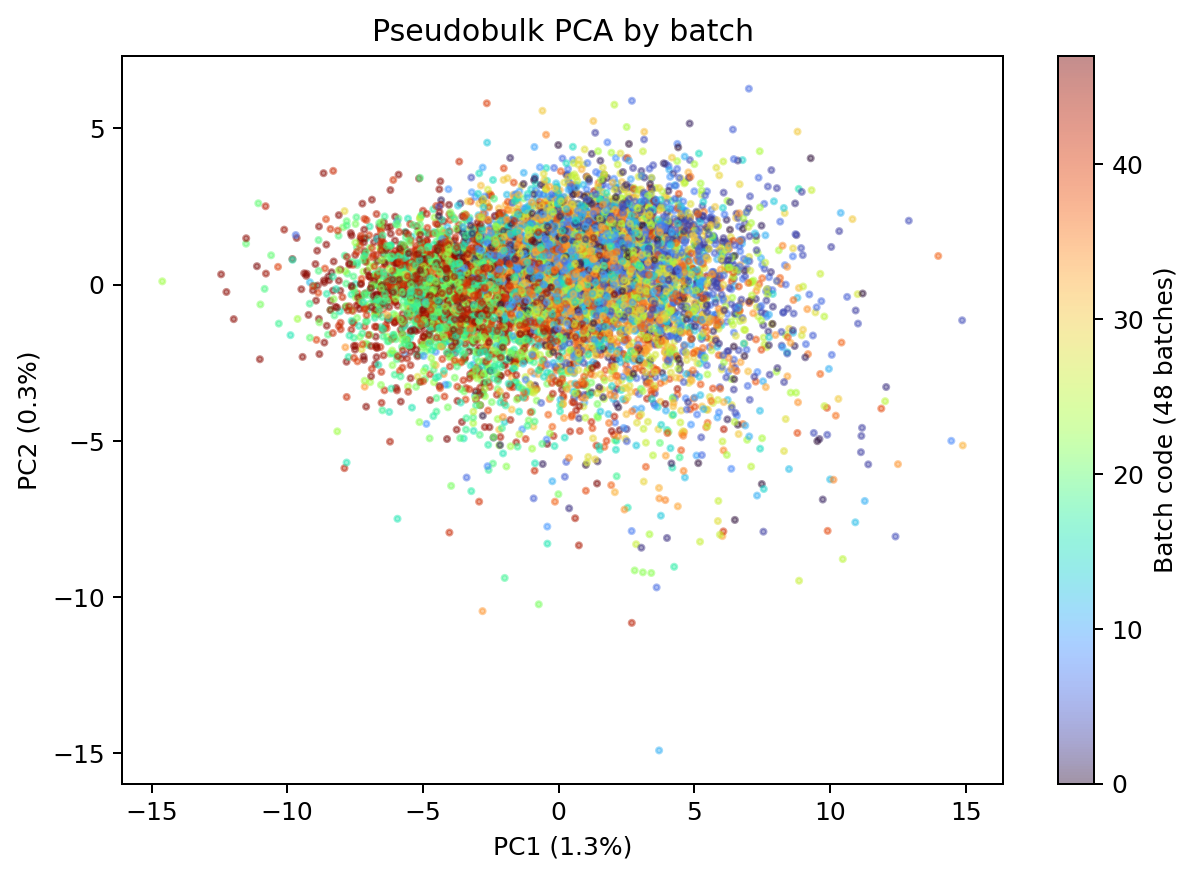

In [2]:
n_pcs = 10
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
first = variance.head(100)
axes[0].plot(first['component'], first['eigenvalue'], color='#42677B', lw=1.2)
axes[0].axvline(n_pcs, color='#9A675B', ls='--', label=f'Retained: {n_pcs}')
axes[0].set(xlabel='Principal component', ylabel='Eigenvalue', title='PCA scree')
axes[0].legend(frameon=False)
axes[1].plot(variance['component'], variance['cumulative_explained_variance_ratio'], color='#42677B')
axes[1].axvline(n_pcs, color='#9A675B', ls='--')
axes[1].set(xlabel='Number of components', ylabel='Cumulative variance', ylim=(0, 1.01), title='Explained variance')
fig.tight_layout()
fig.savefig(out / 'pca_scree.png', dpi=180, bbox_inches='tight')
display(Image(filename=out / 'pca_scree.png'))
plt.close(fig)

batch_codes, batch_labels = pd.factorize(scores['batch'], sort=True)
fig, ax = plt.subplots(figsize=(7, 5))
scatter = ax.scatter(scores['PC1'], scores['PC2'], c=batch_codes, s=5, alpha=.45, cmap='turbo', rasterized=True)
ax.set(xlabel=f"PC1 ({variance.loc[0, 'explained_variance_ratio']:.1%})", ylabel=f"PC2 ({variance.loc[1, 'explained_variance_ratio']:.1%})", title='Pseudobulk PCA by batch')
fig.colorbar(scatter, ax=ax, label=f'Batch code ({len(batch_labels)} batches)')
fig.tight_layout()
fig.savefig(out / 'pca_scores_pc1_pc2.png', dpi=180, bbox_inches='tight')
display(Image(filename=out / 'pca_scores_pc1_pc2.png'))
plt.close(fig)

## Wald versus local-robust inference

Point estimates and clustered SEs are shared. The local-robust rule adds worst-case moment bias to the interval/test, then BH is applied to its p-values separately. Comparisons below use a common complete-case universe for all three methods and both inference rules.

In [3]:
qcols = [f'q_{m}' for m in methods] + [f'q_robust_{m}' for m in methods]
complete = results.loc[results[qcols].notna().all(axis=1)].copy()
if complete.empty:
    raise ValueError('No pairs have all six q-values.')
print(f'Common complete-case universe: {len(complete):,}/{len(results):,} pairs.')
def calls(frame, mode):
    prefix = 'q_robust_' if mode == 'Local robust' else 'q_'
    return pd.DataFrame({m: frame[f'{prefix}{m}'].le(alpha).to_numpy() for m in methods}, index=frame.index)
wald_calls = calls(complete, 'Wald')
local_calls = calls(complete, 'Local robust')
rows = []
for m in methods:
    w, l = wald_calls[m], local_calls[m]
    rows.append({'method': labels[m], 'wald_hits': int(w.sum()), 'local_hits': int(l.sum()), 'both_hits': int((w & l).sum()), 'wald_only': int((w & ~l).sum()), 'local_only': int((~w & l).sum()), 'mean_wald_ci_width': float((complete[f'ci_high_{m}'] - complete[f'ci_low_{m}']).mean()), 'mean_local_ci_width': float((complete[f'ci_high_robust_{m}'] - complete[f'ci_low_robust_{m}']).mean())})
inference_summary = pd.DataFrame(rows)
inference_summary.to_csv(out / 'wald_vs_local_worst_case_summary.csv', index=False)
display(inference_summary)

Common complete-case universe: 426,000/426,000 pairs.


,method,wald_hits,local_hits,both_hits,wald_only,local_only,mean_wald_ci_width,mean_local_ci_width
0,IV,99329,82013,82013,17316,0,1.366354,1.457717
1,SV,28582,18653,18653,9929,0,0.406661,0.454686
2,Two-step GMM,84363,70132,70132,14231,0,0.385628,0.425275


## SRP-style overlap: three circles for each inference rule

Each number is the count of perturbation–outcome pairs significant in **exactly** that combination of IV, SV, and GMM. The two panels use the same tested pairs. Circle areas are illustrative, not proportional to the counts.

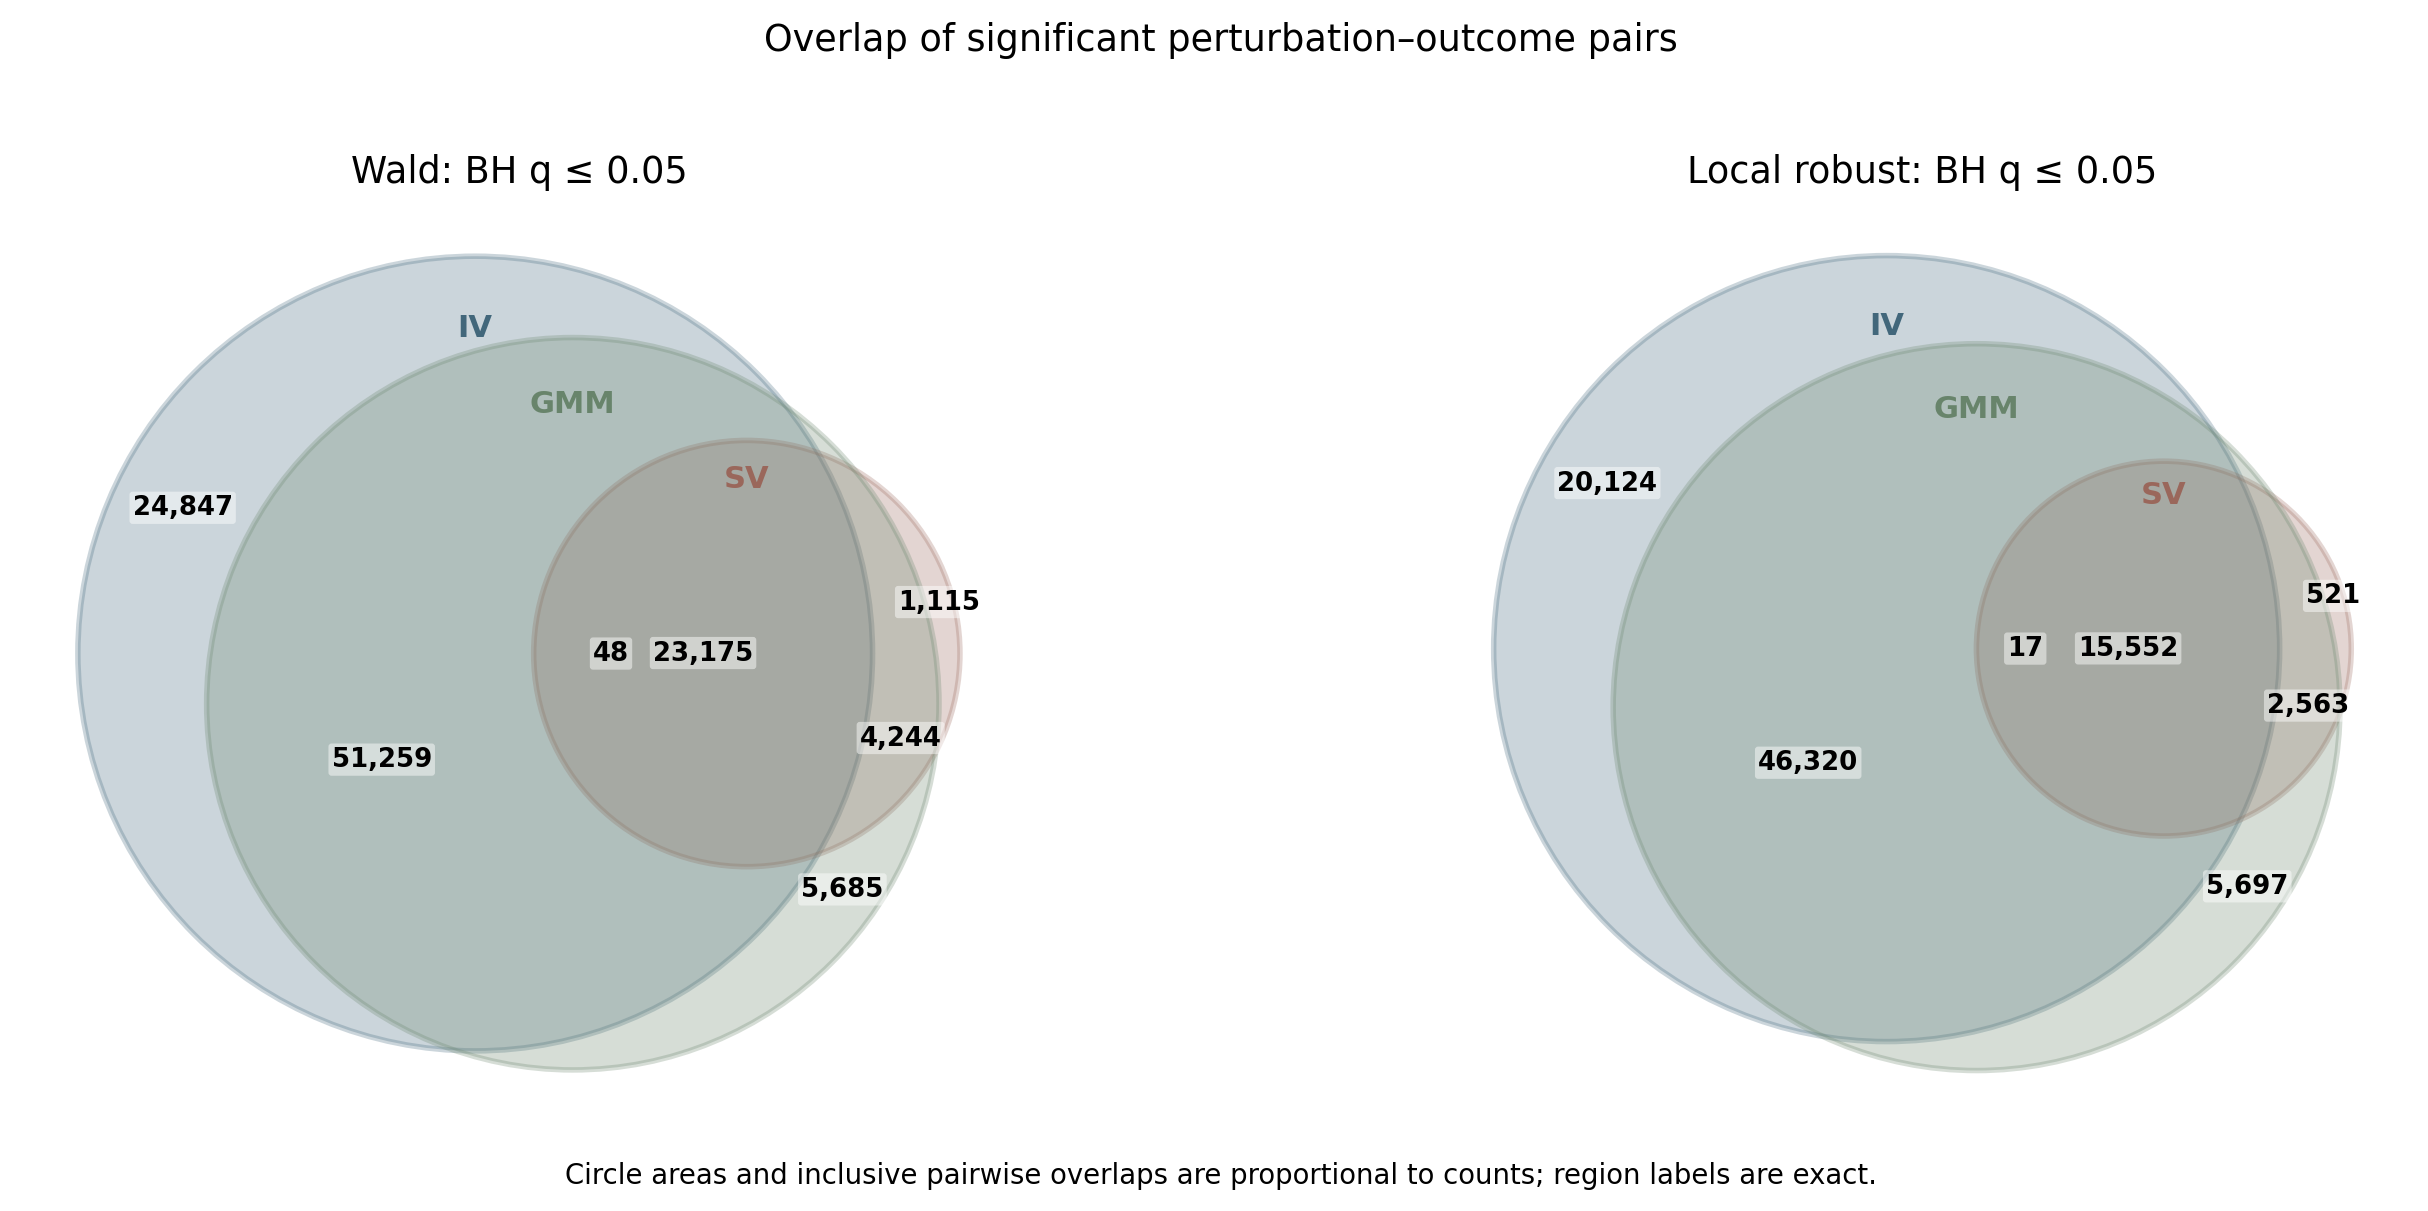

Wald exclusive regions: {(1, 0, 0): 24847, (0, 1, 0): 1115, (0, 0, 1): 5685, (1, 1, 0): 48, (1, 0, 1): 51259, (0, 1, 1): 4244, (1, 1, 1): 23175}
Local robust exclusive regions: {(1, 0, 0): 20124, (0, 1, 0): 521, (0, 0, 1): 5697, (1, 1, 0): 17, (1, 0, 1): 46320, (0, 1, 1): 2563, (1, 1, 1): 15552}


In [4]:
from scipy.optimize import brentq

def overlap_counts(call_table):
    bits = call_table[list(methods)].astype(int).to_numpy()
    return {key: int(((bits == np.array(key)).all(axis=1)).sum()) for key in ((1,0,0),(0,1,0),(0,0,1),(1,1,0),(1,0,1),(0,1,1),(1,1,1))}

def circle_intersection_area(r1, r2, distance):
    if distance >= r1 + r2:
        return 0.0
    if distance <= abs(r1-r2):
        return np.pi * min(r1,r2)**2
    a1 = np.arccos(np.clip((distance**2+r1**2-r2**2)/(2*distance*r1),-1,1))
    a2 = np.arccos(np.clip((distance**2+r2**2-r1**2)/(2*distance*r2),-1,1))
    lens = .5*np.sqrt(max(0,(-distance+r1+r2)*(distance+r1-r2)*(distance-r1+r2)*(distance+r1+r2)))
    return r1**2*a1+r2**2*a2-lens

def distance_for_overlap(r1, r2, target):
    target = min(max(float(target),0),np.pi*min(r1,r2)**2)
    if target <= 0:
        return r1+r2
    if np.isclose(target,np.pi*min(r1,r2)**2):
        return abs(r1-r2)
    return brentq(lambda d: circle_intersection_area(r1,r2,d)-target,
                  abs(r1-r2)+1e-10,r1+r2-1e-10)

def proportional_circle_layout(counts):
    # Exact set areas and inclusive pairwise-intersection areas determine radii/distances.
    set_counts = np.array([
        sum(value for key,value in counts.items() if key[0]),
        sum(value for key,value in counts.items() if key[1]),
        sum(value for key,value in counts.items() if key[2]),
    ],dtype=float)
    scale = 1.28/np.sqrt(set_counts.max()/np.pi)
    radii = np.sqrt(set_counts/np.pi)*scale
    triple = counts[(1,1,1)]
    pair_counts = np.array([counts[(1,1,0)]+triple, counts[(1,0,1)]+triple, counts[(0,1,1)]+triple],dtype=float)
    pair_areas = pair_counts*scale**2
    d12 = distance_for_overlap(radii[0],radii[1],pair_areas[0])
    d13 = distance_for_overlap(radii[0],radii[2],pair_areas[1])
    d23 = distance_for_overlap(radii[1],radii[2],pair_areas[2])
    # Realizable triangle; numerical clipping only guards against roundoff/incompatible summaries.
    cosine = np.clip((d12**2+d13**2-d23**2)/(2*d12*d13),-1,1)
    centers = np.array([[0.,0.],[d12,0.],[d13*cosine,-d13*np.sqrt(max(0,1-cosine**2))]])
    centers -= centers.mean(axis=0)
    return centers,radii,set_counts,pair_counts

def region_label_positions(centers,radii):
    pad=.18
    xmin=np.min(centers[:,0]-radii)-pad; xmax=np.max(centers[:,0]+radii)+pad
    ymin=np.min(centers[:,1]-radii)-pad; ymax=np.max(centers[:,1]+radii)+pad
    xs=np.linspace(xmin,xmax,700); ys=np.linspace(ymin,ymax,600)
    xx,yy=np.meshgrid(xs,ys)
    signed=np.stack([r-np.hypot(xx-x,yy-y) for (x,y),r in zip(centers,radii)],axis=0)
    result={}
    for key in ((1,0,0),(0,1,0),(0,0,1),(1,1,0),(1,0,1),(0,1,1),(1,1,1)):
        desired=np.array(key,dtype=bool)[:,None,None]
        feasible=np.all((signed>=0)==desired,axis=0)
        margin=np.min(np.where(desired,signed,-signed),axis=0)
        margin=np.where(feasible,margin,-np.inf)
        if np.isfinite(margin).any():
            row,col=np.unravel_index(np.argmax(margin),margin.shape)
            result[key]=(xx[row,col],yy[row,col])
        else:
            included=np.flatnonzero(key)
            result[key]=tuple(centers[included].mean(axis=0))
    return result,(xmin,xmax,ymin,ymax)

def draw_proportional_venn(ax,counts,title):
    centers,radii,set_counts,pair_counts=proportional_circle_layout(counts)
    method_names=('IV','SV','GMM')
    method_keys=('iv','sv','gmm')
    for (x,y),radius,key,name in zip(centers,radii,method_keys,method_names):
        ax.add_patch(Circle((x,y),radius,facecolor=colors[key],edgecolor=colors[key],alpha=.27,linewidth=1.8))
        ax.text(x,y+radius*.82,name,color=colors[key],weight='bold',ha='center',va='center',fontsize=10)
    positions,limits=region_label_positions(centers,radii)
    for key,(x,y) in positions.items():
        ax.text(x,y,f'{counts[key]:,}',ha='center',va='center',fontsize=8.5,weight='bold',
                bbox=dict(boxstyle='round,pad=.12',facecolor='white',edgecolor='none',alpha=.48))
    xmin,xmax,ymin,ymax=limits
    ax.set(xlim=(xmin,xmax),ylim=(ymin,ymax),aspect='equal',title=title)
    ax.axis('off')
    return set_counts,pair_counts

venn_counts={'Wald':overlap_counts(wald_calls),'Local robust':overlap_counts(local_calls)}
fig,axes=plt.subplots(1,2,figsize=(13,5.5))
for ax,(mode,count) in zip(axes,venn_counts.items()):
    draw_proportional_venn(ax,count,f'{mode}: BH q ≤ {alpha}')
fig.suptitle('Overlap of significant perturbation–outcome pairs')
fig.text(.5,.02,'Circle areas and inclusive pairwise overlaps are proportional to counts; region labels are exact.',ha='center',fontsize=9)
fig.tight_layout(rect=(0,.04,1,.96))
fig.savefig(out/'wald_vs_local_iv_sv_gmm_venn.png',dpi=220,bbox_inches='tight')
display(Image(filename=out/'wald_vs_local_iv_sv_gmm_venn.png'))
plt.close(fig)
for mode,count in venn_counts.items():
    print(mode,'exclusive regions:',count)


## Same analysis for both rules: discovery counts and coefficient distributions

The histograms select significant pairs separately under Wald and local robust, while the coefficient estimate for a given pair remains the same.

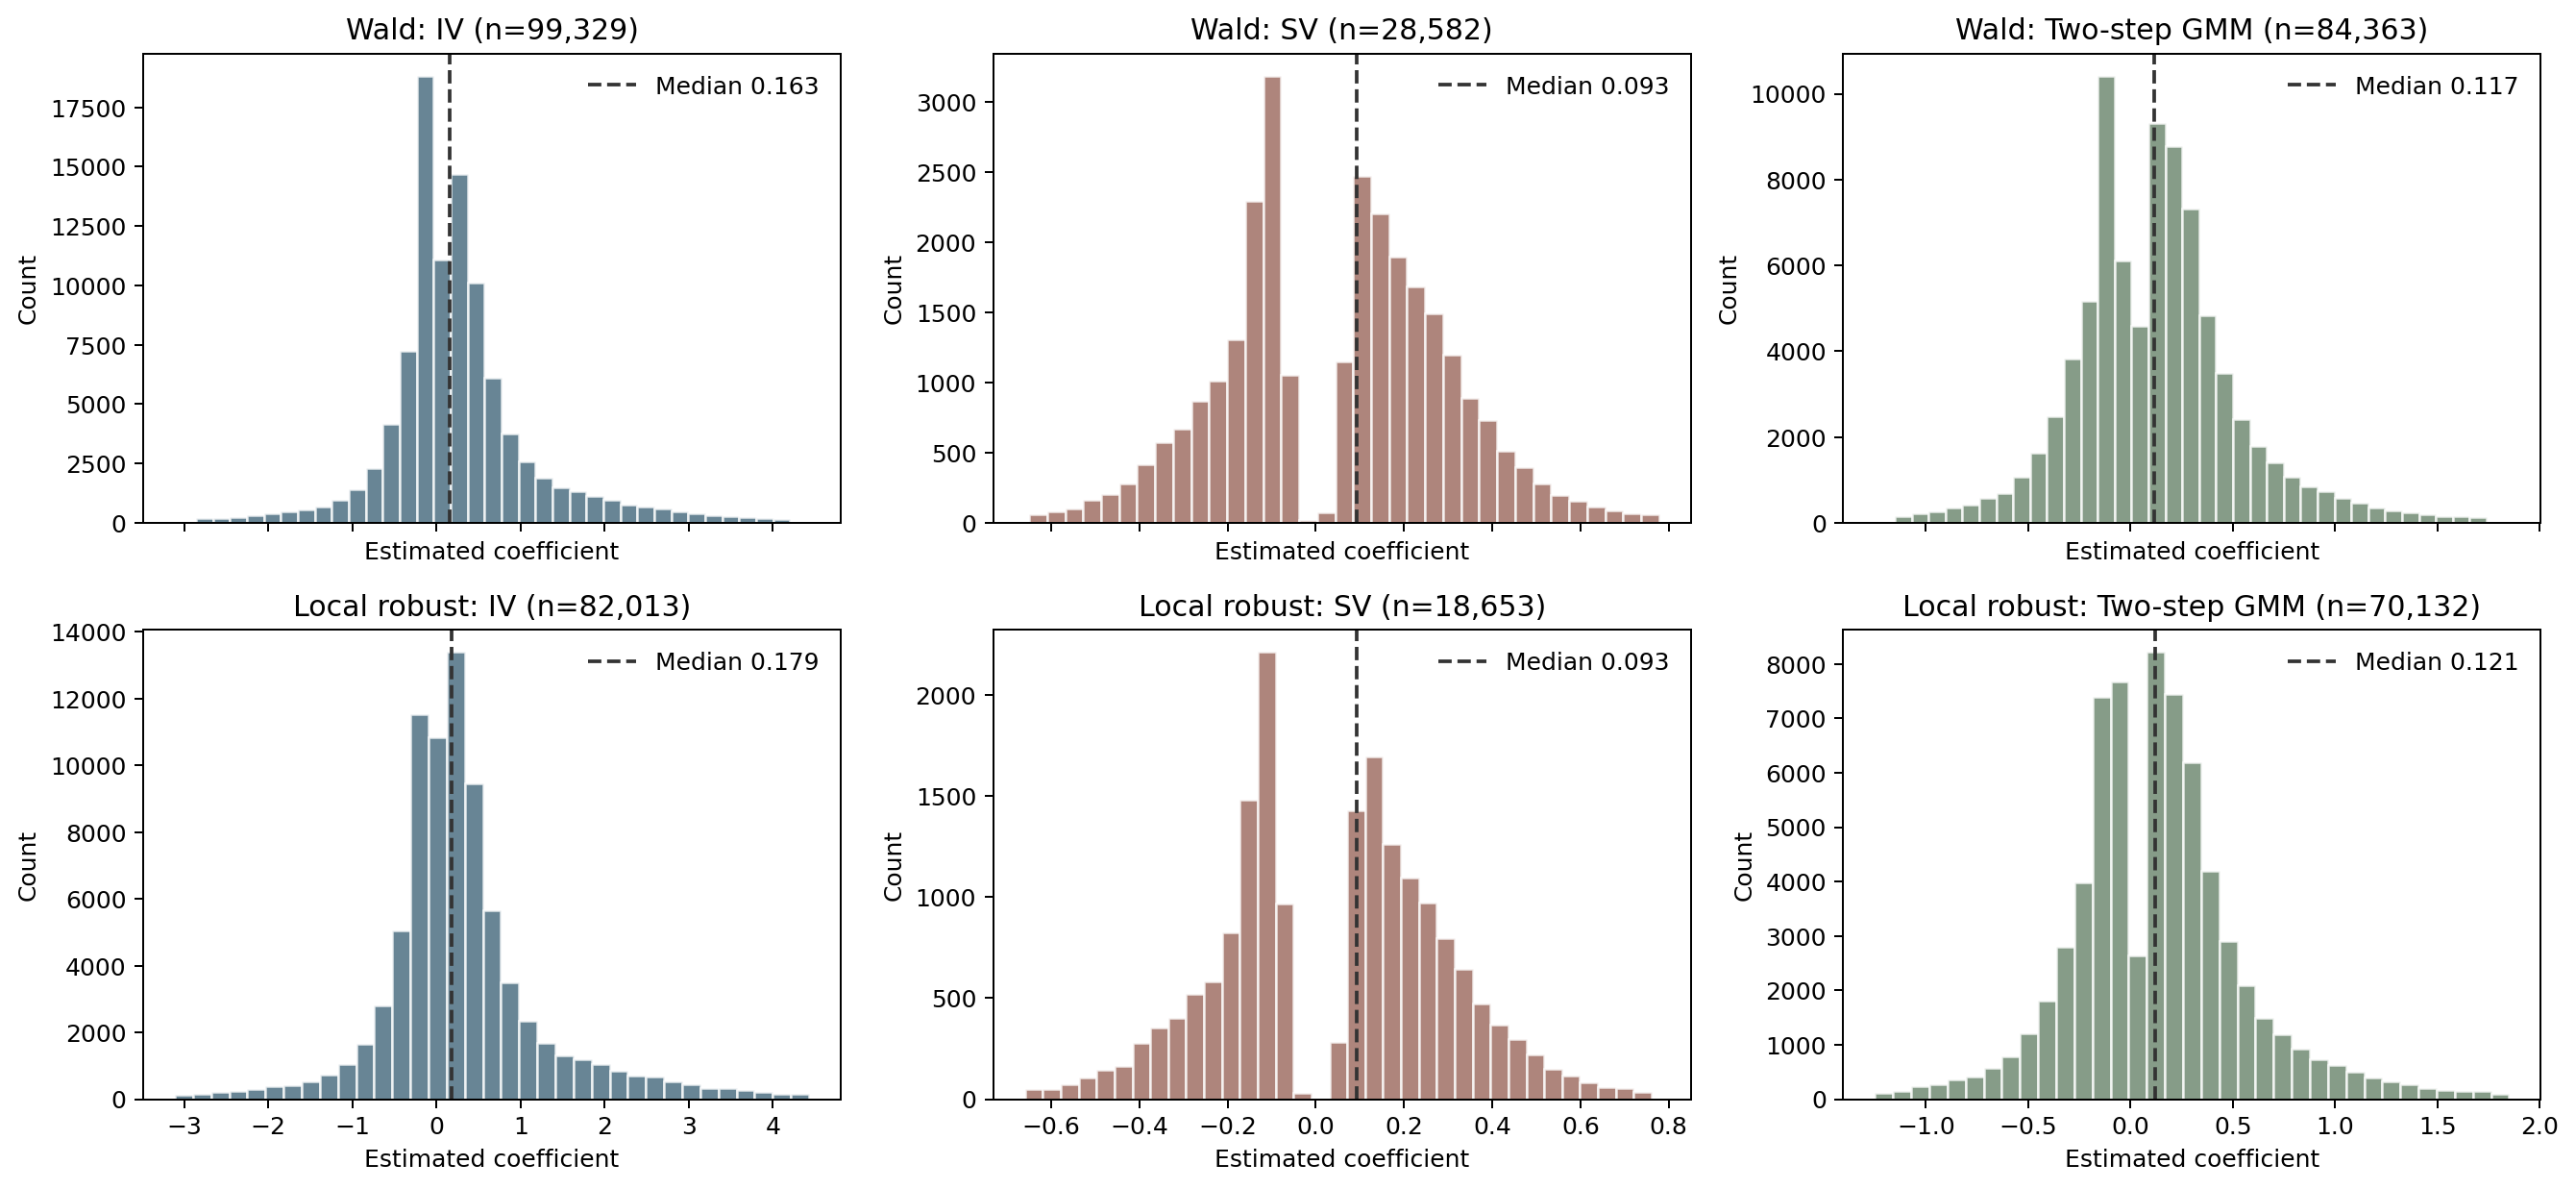

,inference,method,n_significant,median_beta
0,Wald,IV,99329,0.162936
1,Wald,SV,28582,0.092532
2,Wald,Two-step GMM,84363,0.116862
3,Local robust,IV,82013,0.179017
4,Local robust,SV,18653,0.092676
5,Local robust,Two-step GMM,70132,0.121403


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex='col')
summary_rows = []
for row,(mode,table) in enumerate((('Wald',wald_calls),('Local robust',local_calls))):
    for col,m in enumerate(methods):
        values = complete.loc[table[m],f'beta_{m}'].dropna().to_numpy()
        ax = axes[row,col]
        if len(values):
            lo,hi = np.quantile(values,[.01,.99])
            shown = values[(values>=lo)&(values<=hi)]
            ax.hist(shown,bins=35,color=colors[m],alpha=.8,edgecolor='white')
            ax.axvline(np.median(values),color='#333333',ls='--',label=f'Median {np.median(values):.3f}')
            ax.legend(frameon=False)
        else:
            ax.text(.5,.5,'No hits',ha='center',va='center',transform=ax.transAxes)
        ax.set(title=f'{mode}: {labels[m]} (n={len(values):,})',xlabel='Estimated coefficient',ylabel='Count')
        summary_rows.append({'inference':mode,'method':labels[m],'n_significant':len(values),'median_beta':float(np.median(values)) if len(values) else np.nan})
fig.tight_layout()
fig.savefig(out / 'wald_vs_local_significant_coefficient_histograms.png',dpi=180,bbox_inches='tight')
display(Image(filename=out / 'wald_vs_local_significant_coefficient_histograms.png'))
plt.close(fig)
discovery_summary = pd.DataFrame(summary_rows)
discovery_summary.to_csv(out / 'wald_vs_local_discovery_summary.csv',index=False)
display(discovery_summary)

## Agreement and matched Wilcoxon comparison

For each rule, Wilcoxon raw p-values are BH-adjusted over the same outcome-gene family within each perturbation. We compare individual IV/SV/GMM calls and their all-three intersection with those matched Wilcoxon calls. This is an agreement analysis, not ground-truth validation.

In [6]:
comparison = complete.merge(wilcoxon,on=['perturbation','y_gene'],how='left',validate='one_to_one')
if comparison['wilcoxon_p_raw'].isna().all():
    raise ValueError('No matched Wilcoxon p-values.')
def bh_adjust(pvalues):
    pvalues=np.asarray(pvalues,dtype=float)
    adjusted=np.full(pvalues.shape,np.nan)
    valid=np.isfinite(pvalues)
    if valid.any():
        vals=pvalues[valid]; order=np.argsort(vals)
        ranked=vals[order]*len(vals)/np.arange(1,len(vals)+1)
        ranked=np.minimum.accumulate(ranked[::-1])[::-1]
        reordered=np.empty_like(vals); reordered[order]=np.clip(ranked,0,1)
        adjusted[valid]=reordered
    return adjusted
comparison['wilcoxon_q_same_y']=comparison.groupby('perturbation',sort=False)['wilcoxon_p_raw'].transform(bh_adjust)
comparison['wilcoxon_hit']=comparison['wilcoxon_q_same_y'].le(alpha)
rows=[]
for mode in ('Wald','Local robust'):
    table=calls(comparison,mode)
    selections={**{m:table[m] for m in methods},'all_three':table.all(axis=1)}
    for m,selected in selections.items():
        w=comparison['wilcoxon_hit']
        rows.append({'inference':mode,'selection':labels.get(m,'All three'),'n_selected':int(selected.sum()),'selected_and_wilcoxon':int((selected&w).sum()),'selected_not_wilcoxon':int((selected&~w).sum()),'wilcoxon_only':int((~selected&w).sum()),'neither':int((~selected&~w).sum())})
wilcoxon_agreement=pd.DataFrame(rows)
wilcoxon_agreement.to_csv(out/'wald_vs_local_wilcoxon_agreement.csv',index=False)
display(wilcoxon_agreement)
for mode in ('Wald','Local robust'):
    table=calls(comparison,mode)
    n=table.sum(axis=1)
    print(mode, {'all_three':int((n==3).sum()),'none':int((n==0).sum()),'mixed':int(n.isin((1,2)).sum())})

,inference,selection,n_selected,selected_and_wilcoxon,selected_not_wilcoxon,wilcoxon_only,neither
0,Wald,IV,99329,97082,2247,112192,214479
1,Wald,SV,28582,26237,2345,183037,214381
2,Wald,Two-step GMM,84363,80259,4104,129015,212622
3,Wald,All three,23175,22868,307,186406,216419
4,Local robust,IV,82013,81038,975,128236,215751
5,Local robust,SV,18653,17748,905,191526,215821
6,Local robust,Two-step GMM,70132,68085,2047,141189,214679
7,Local robust,All three,15552,15456,96,193818,216630


Wald {'all_three': 23175, 'none': 315627, 'mixed': 87198}
Local robust {'all_three': 15552, 'none': 335206, 'mixed': 75242}


## Wald/local rank comparison with Wilcoxon

Within each perturbation, rank outcomes by each method's raw p-value, average the three IV/SV/GMM ranks, and compare that mean rank with the Wilcoxon raw-p rank. The same procedure is applied separately to Wald and local-robust p-values; this preserves the earlier notebook's rank analysis while making the inference-rule comparison explicit.

,count,mean,median,min,max
inference,,,,,
Local robust,213,0.517578,0.578141,0.002409,0.884797
Wald,213,0.517588,0.578402,0.002025,0.885173


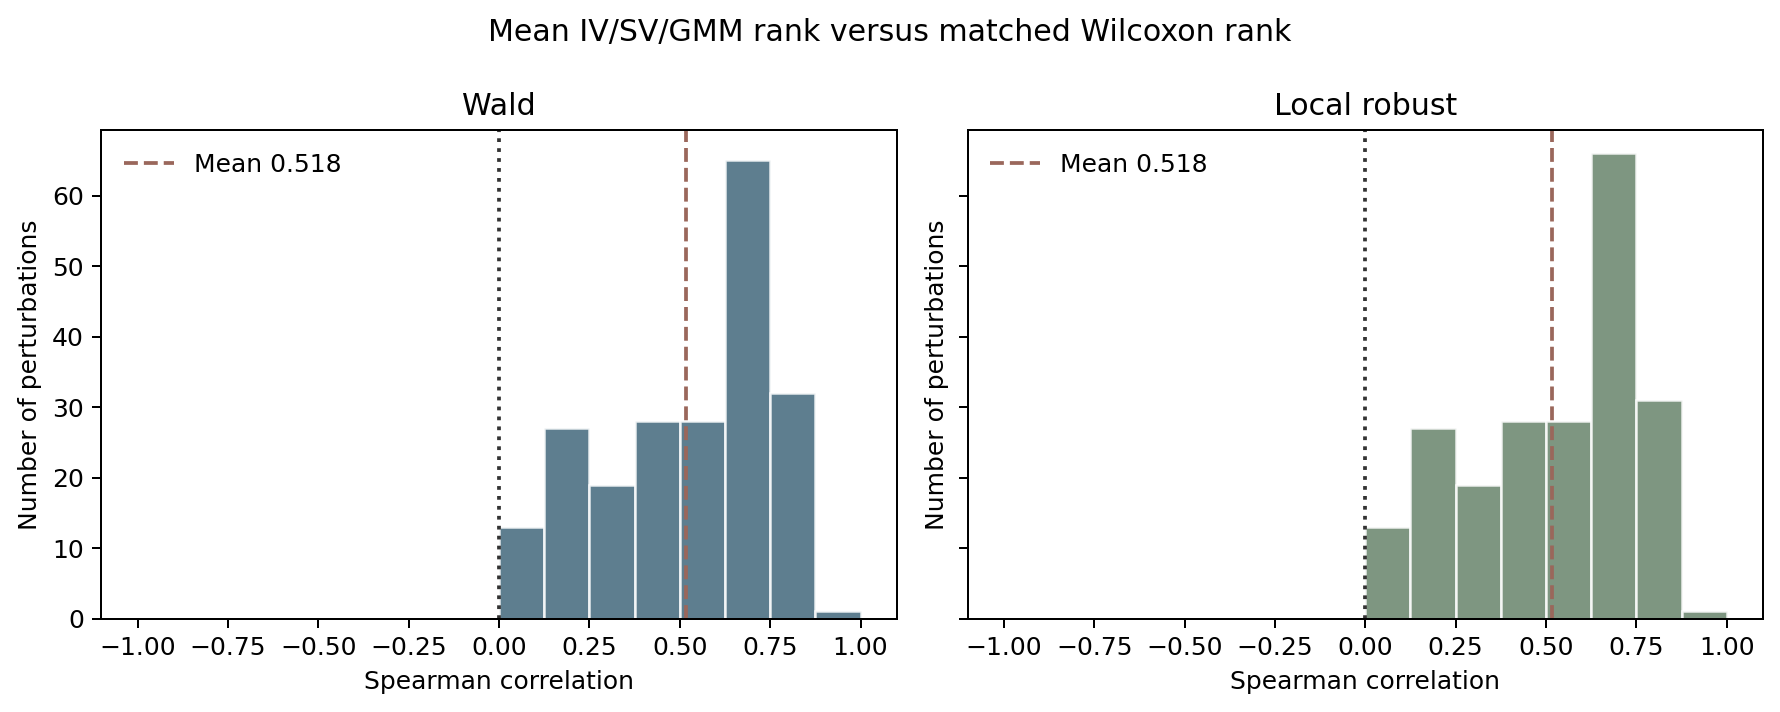

In [7]:
from scipy.stats import spearmanr
comparison['wilcoxon_rank'] = comparison.groupby('perturbation', sort=False)['wilcoxon_p_raw'].rank(method='average')
rank_rows = []
rank_summary_rows = []
for mode, prefix in (('Wald', 'p_'), ('Local robust', 'p_robust_')):
    ranks = []
    for method in methods:
        col = f'{mode.lower().replace(" ", "_")}_{method}_rank'
        comparison[col] = comparison.groupby('perturbation', sort=False)[f'{prefix}{method}'].rank(method='average')
        ranks.append(col)
    mean_col = f'{mode.lower().replace(" ", "_")}_mean_rank'
    comparison[mean_col] = comparison[ranks].mean(axis=1, skipna=False)
    for perturbation, group in comparison.groupby('perturbation', sort=False):
        paired = group[[mean_col, 'wilcoxon_rank']].dropna()
        if len(paired) >= 2 and paired[mean_col].nunique() > 1 and paired['wilcoxon_rank'].nunique() > 1:
            rho, pvalue = spearmanr(paired[mean_col], paired['wilcoxon_rank'])
        else:
            rho, pvalue = np.nan, np.nan
        rank_rows.append({'inference': mode, 'perturbation': perturbation, 'n_genes': len(paired), 'spearman_rho': rho, 'spearman_pvalue': pvalue})
rank_correlations = pd.DataFrame(rank_rows)
rank_correlations.to_csv(out / 'wald_vs_local_rank_correlations.csv', index=False)
comparison.to_csv(out / 'wald_vs_local_pair_comparison.csv.gz', index=False, compression='gzip')
display(rank_correlations.groupby('inference')['spearman_rho'].agg(['count','mean','median','min','max']))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, mode, color in zip(axes, ('Wald','Local robust'), ('#42677B','#68846B')):
    values = rank_correlations.loc[rank_correlations['inference'].eq(mode), 'spearman_rho'].dropna()
    ax.hist(values, bins=np.linspace(-1,1,17), color=color, edgecolor='white', alpha=.85)
    ax.axvline(values.mean(), color='#9A675B', ls='--', label=f'Mean {values.mean():.3f}')
    ax.axvline(0, color='#333333', ls=':')
    ax.set(title=mode, xlabel='Spearman correlation', ylabel='Number of perturbations')
    ax.legend(frameon=False)
fig.suptitle('Mean IV/SV/GMM rank versus matched Wilcoxon rank')
fig.tight_layout()
fig.savefig(out / 'wald_vs_local_rank_correlations.png', dpi=180, bbox_inches='tight')
display(Image(filename=out / 'wald_vs_local_rank_correlations.png'))
plt.close(fig)

## GO Biological Process enrichment

Computed by `python code/experiments/replogle/run_go_analysis.py` from the saved pair-level results and [official human GO annotations](https://geneontology.org/docs/download-go-annotations/) plus [go-basic ontology](https://geneontology.org/docs/download-ontology/). This notebook **only reads the GO outputs**. For each perturbation and selection (Wald IV/SV/GMM, local IV/SV/GMM, matched-family Wilcoxon), over-representation uses the hypergeometric test with the same 2,000 tested outcome genes as background; annotations are propagated through `is_a` and `part_of`. GO:BP terms covering 2 to 1,999 background genes are tested, then BH-adjusted within each perturbation/selection. The annotation release and checksums are saved in `go_bp_manifest.json`.

**Important:** The pair count now matches the SRP design, but this workflow additionally compares Wald and local-robust inference; use only freshly regenerated outputs when interpreting GO counts.

GO:BP background: 2000 tested outcomes; 1790 directly annotated; 4795 terms tested per perturbation/selection.
Human GAF date: !date-generated: 2026-07-28 19:42


,selection,n_perturbations,selected_pairs,significant_perturbation_term_pairs,perturbations_with_go_hits
0,local_gmm,213,70132,1655,89
1,local_iv,213,82013,1621,92
2,local_sv,213,18653,918,45
3,wald_gmm,213,84363,1403,80
4,wald_iv,213,99329,1576,91
5,wald_sv,213,28582,886,51
6,wilcoxon,213,209274,894,76


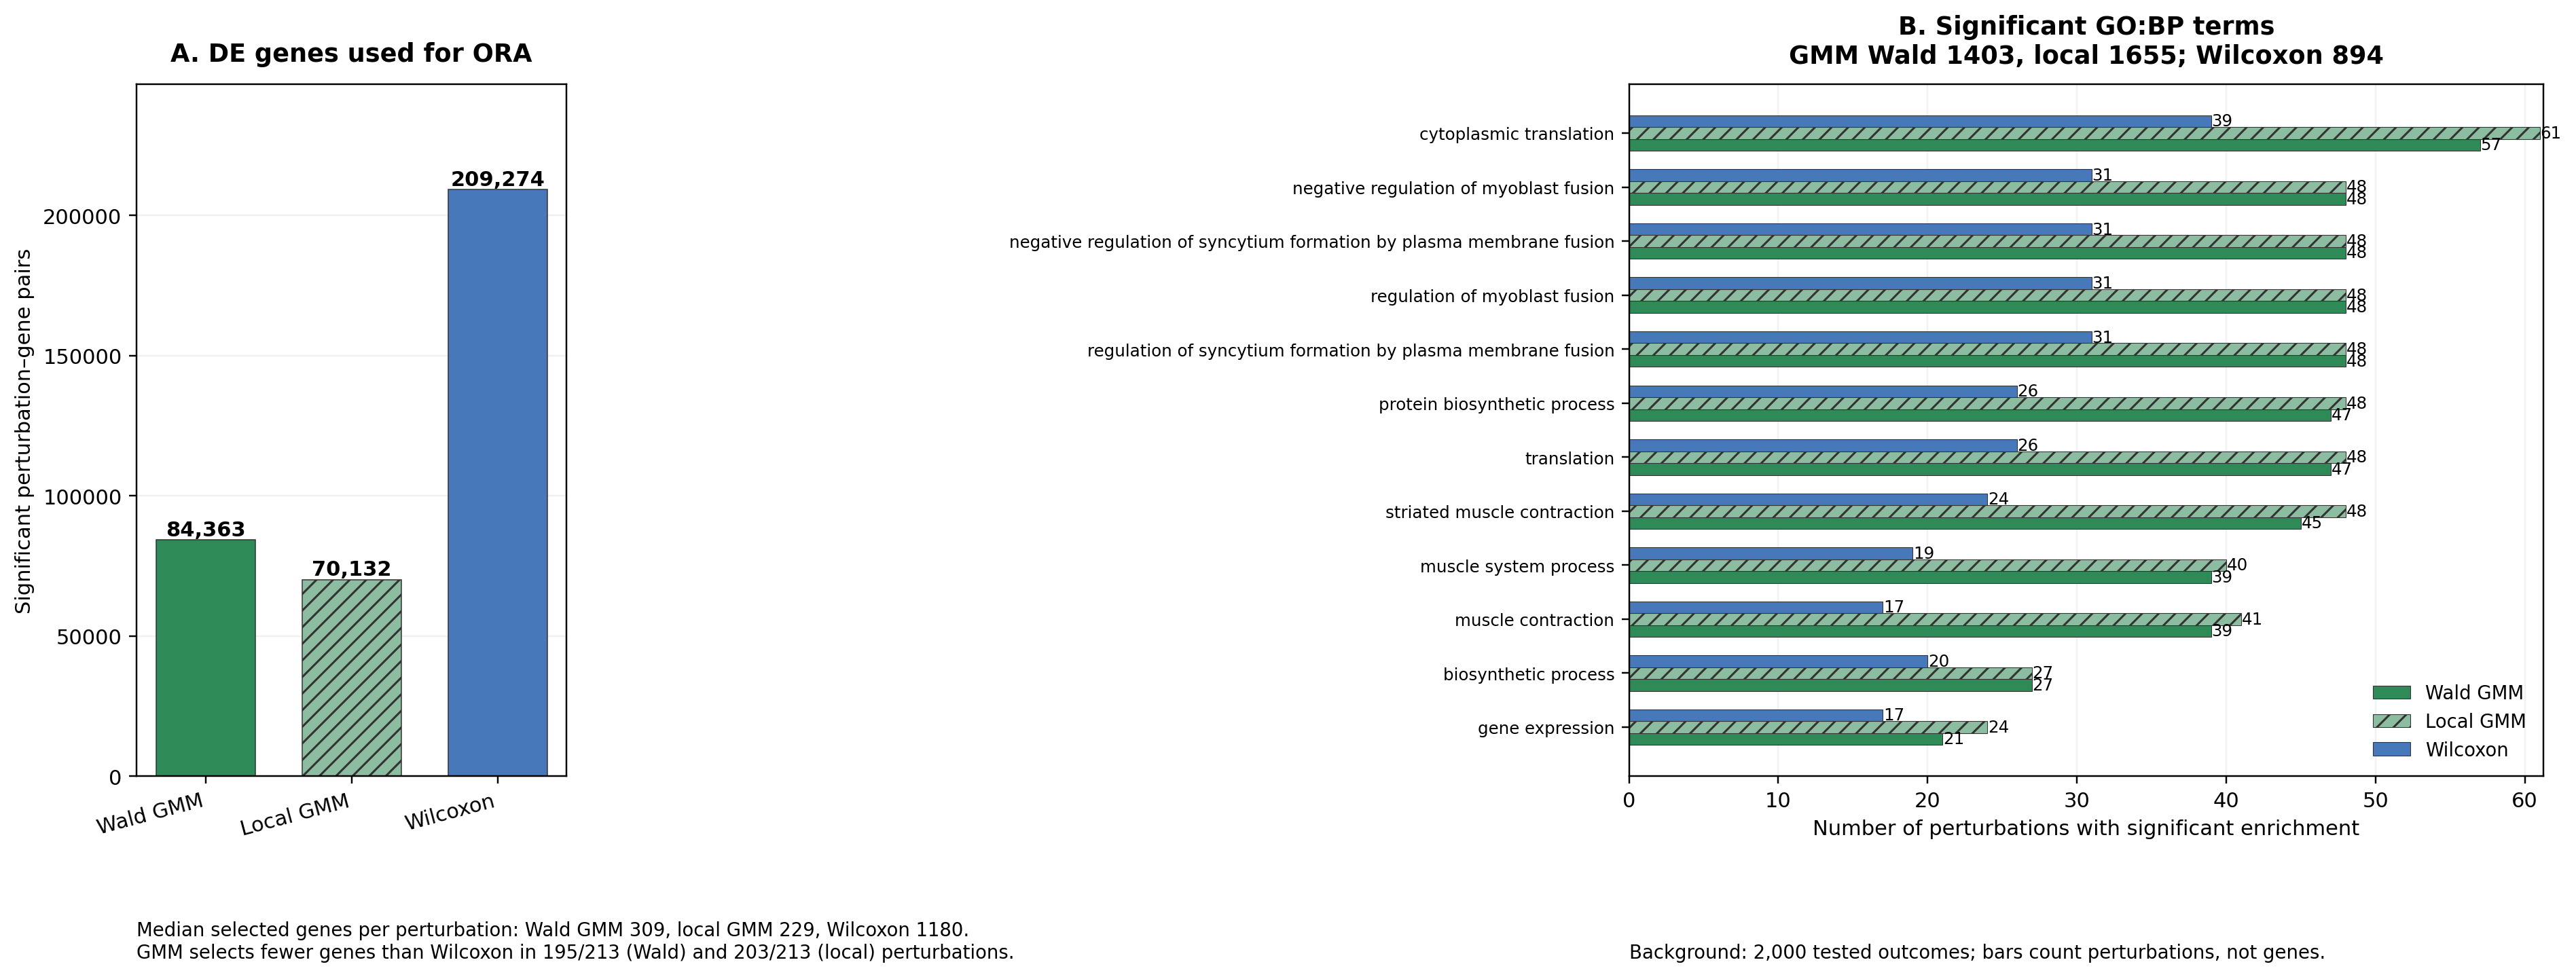

,selection,go_id,go_name,n_perturbations,minimum_q
8,local_gmm,GO:0002181,cytoplasmic translation,61,7.847601e-20
178,local_gmm,GO:0034242,negative regulation of syncytium formation by ...,48,6.323955e-15
272,local_gmm,GO:0060142,regulation of syncytium formation by plasma me...,48,6.323955e-15
313,local_gmm,GO:1901739,regulation of myoblast fusion,48,6.323955e-15
314,local_gmm,GO:1901740,negative regulation of myoblast fusion,48,6.323955e-15
41,local_gmm,GO:0006412,translation,48,1.427173e-13
304,local_gmm,GO:0160307,protein biosynthetic process,48,1.427173e-13
59,local_gmm,GO:0006941,striated muscle contraction,48,2.148107e-13
58,local_gmm,GO:0006936,muscle contraction,41,5.608726e-12
21,local_gmm,GO:0003012,muscle system process,40,7.370221e-12


selection,wald_gmm,local_gmm,wilcoxon
perturbation,,,
AATF,15,20,8
ABCF1,12,3,0
AHCTF1,0,0,4
ANKRD11,0,0,26
ARCN1,0,0,12
ARGLU1,0,0,8
ATP6V1B2,10,35,10
BCR,0,0,17
BDP1,28,13,4


In [8]:
import json
manifest_path = out / 'go_bp_manifest.json'
if not manifest_path.is_file():
    raise FileNotFoundError('GO outputs are missing. Run python code/experiments/replogle/run_go_analysis.py first.')
manifest = json.loads(manifest_path.read_text())
go_overview = pd.read_csv(out / 'go_bp_overview.csv')
go_per_perturbation = pd.read_csv(out / 'go_bp_per_perturbation.csv')
go_recurrent = pd.read_csv(out / 'go_bp_recurrent_terms.csv')
print(f"GO:BP background: {manifest['n_tested_outcome_genes']} tested outcomes; "
      f"{manifest['n_genes_with_direct_bp_annotation']} directly annotated; "
      f"{manifest['n_tested_bp_terms']} terms tested per perturbation/selection.")
print('Human GAF date:', next((line for line in manifest['gaf_header'] if line.startswith('!date-generated:')), 'not recorded'))
display(go_overview)

# SRP-poster layout: A = selected DE pairs; B = recurrent significant GO:BP terms.
selections = ['wald_gmm', 'local_gmm', 'wilcoxon']
short_labels = ['Wald GMM', 'Local GMM', 'Wilcoxon']
colors_go = ['#2E8B57', '#8DBDA0', '#4778BA']
counts = go_overview.set_index('selection').reindex(selections)['selected_pairs'].astype(int)
term_pivot = go_recurrent[go_recurrent['selection'].isin(selections)].pivot_table(
    index=['go_id', 'go_name'], columns='selection', values='n_perturbations', fill_value=0
)
if term_pivot.empty:
    raise ValueError('No significant GMM or Wilcoxon GO:BP terms to display.')
term_pivot = term_pivot.reindex(columns=selections, fill_value=0)
term_pivot['total'] = term_pivot[selections].sum(axis=1)
term_pivot = term_pivot.sort_values(['total', 'go_name'], ascending=[False, True]).head(12).iloc[::-1]

fig = plt.figure(figsize=(18, 7.6))
ax_a = fig.add_axes([.065, .23, .16, .61])
ax_b = fig.add_axes([.62, .23, .34, .61])
bars = ax_a.bar(range(3), counts, color=colors_go, edgecolor='#333333', linewidth=.5, width=.68)
bars[1].set_hatch('///')
for bar, value in zip(bars, counts):
    ax_a.text(bar.get_x()+bar.get_width()/2, value+35, f'{value:,}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax_a.set_xticks(range(3), short_labels, rotation=15, ha='right')
ax_a.set_ylim(0, max(counts)*1.18)
ax_a.set_ylabel('Significant perturbation–gene pairs')
ax_a.set_title('A. DE genes used for ORA', fontsize=12, fontweight='bold', pad=11)
ax_a.grid(axis='y', alpha=.18)
ax_a.set_axisbelow(True)

from matplotlib.patches import Patch
locations = np.arange(len(term_pivot))
bar_height = .22
for j, (selection, label, color) in enumerate(zip(selections, short_labels, colors_go)):
    values = term_pivot[selection].to_numpy(dtype=int)
    y = locations + (j-1)*bar_height
    rects = ax_b.barh(y, values, height=bar_height, color=color, edgecolor='#333333', linewidth=.35,
                      hatch='///' if selection == 'local_gmm' else None, label=label)
    for rect, value in zip(rects, values):
        if value:
            ax_b.text(value+.025, rect.get_y()+rect.get_height()/2, str(value), va='center', fontsize=8)
ax_b.set_yticks(locations, term_pivot.index.get_level_values('go_name'), fontsize=8)
ax_b.set_xlim(0, max(1.25, term_pivot[selections].to_numpy().max()+.25))
if term_pivot[selections].to_numpy().max() == 1:
    ax_b.set_xticks([0, 1])
ax_b.set_xlabel('Number of perturbations with significant enrichment')
assoc = go_overview.set_index('selection')['significant_perturbation_term_pairs']
ax_b.set_title(f'B. Significant GO:BP terms\nGMM Wald {assoc["wald_gmm"]}, local {assoc["local_gmm"]}; Wilcoxon {assoc["wilcoxon"]}',
               fontsize=12, fontweight='bold', pad=10)
ax_b.legend(loc='lower right', frameon=False, fontsize=9)
ax_b.grid(axis='x', alpha=.16)
ax_b.set_axisbelow(True)

selected_matrix = go_per_perturbation.pivot(index='perturbation', columns='selection', values='n_selected')
medians = selected_matrix[selections].median().astype(int)
fewer_wald = int((selected_matrix['wald_gmm'] < selected_matrix['wilcoxon']).sum())
fewer_local = int((selected_matrix['local_gmm'] < selected_matrix['wilcoxon']).sum())
fig.text(.065, .07, f'Median selected genes per perturbation: Wald GMM {medians["wald_gmm"]}, '
         f'local GMM {medians["local_gmm"]}, Wilcoxon {medians["wilcoxon"]}.\n'
         f'GMM selects fewer genes than Wilcoxon in {fewer_wald}/{len(selected_matrix)} (Wald) and {fewer_local}/{len(selected_matrix)} (local) perturbations.',
         fontsize=9, ha='left')
fig.text(.62, .07, f"Background: {manifest['n_tested_outcome_genes']:,} tested outcomes; bars count perturbations, not genes.", fontsize=9, ha='left')
poster_go_path = out / 'go_bp_poster_style_gmm_vs_wilcoxon.png'
fig.savefig(poster_go_path, dpi=220, bbox_inches='tight')
display(Image(filename=poster_go_path))
plt.close(fig)

if not go_recurrent.empty:
    display(go_recurrent.sort_values(['selection','n_perturbations','minimum_q'], ascending=[True,False,True]).head(35))
gmm_comparison = go_per_perturbation.pivot(index='perturbation', columns='selection', values='n_significant_terms')
display(gmm_comparison[['wald_gmm','local_gmm','wilcoxon']].query('wald_gmm > 0 or local_gmm > 0 or wilcoxon > 0').head(20))

## Interpretation

The Wald/local comparison isolates the inference rule: IV/SV/GMM estimates, SEs, tested pairs, and BH families are held fixed. The Wald-only versus local-only counts show which findings change after allowing local moment misspecification. A smaller local hit count is expected when robust intervals widen, but the exact overlap and method ranking are empirical.

GO:BP enrichment uses the same 2,000 tested outcome genes for every selection. Compare Wald, local-robust, and Wilcoxon only after all outputs have been regenerated from this SRP-scale design.